In [4]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

B = "../data/lake/bronze" # ".." means one folder up from notebooks/
books = pd.read_csv(f"{B}/books.csv")
customers = pd.read_csv(f"{B}/customers.csv")
orders = pd.read_csv(f"{B}/orders.csv")
reviews = pd.read_csv(f"{B}/reviews.csv")
print(len(books), len(customers), len(orders), len(reviews))

1000 515 3060 1200


In [15]:
def profile(df):
    return pd.DataFrame({
    "dtype": df.dtypes.astype(str), # the kind of data
    "non_null": df.notna(). sum(), # how many cells are filled
    "null_pct": (df.isna().mean() * 100).round(1), #% of cells that are empty
    "unique": df. nunique(), # how many different values
    "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna() .any() else

    None),
})

profile(customers)

,dtype,non_null,null_pct,unique,example
customer_id,object,515,0.0,500,C0083
full_name,object,515,0.0,88,Nurul binti Omar
email,object,488,5.2,471,nurul.omar61@gmail.com
phone,object,515,0.0,500,015-9735859
mykad,object,515,0.0,500,690914-12-8402
state,object,515,0.0,22,Sabah
signup_date,object,515,0.0,378,2024-01-03


In [19]:
checks = {
    "customers: duplicate rows": customers.duplicated().sum(),
    "customers: missing email": customers["email"].isna().sum(),
    "orders: duplicate order_id": orders["order_id"].duplicated().sum(),
    "orders: quantity <= 0": (orders["quantity"] <= 0).sum(),
    "orders: date not YYYY-MM-DD": pd.to_datetime(
        orders["order_date"], format="%Y-%m-%d", errors="coerce"
    ).isna().sum(),
    "orders: unknown customer_id": (
        ~orders["customer_id"].isin(customers["customer_id"])
    ).sum(),
    "orders: unknown book_id": (~orders["book_id"].isin(books["book_id"])).sum(),
    "reviews: empty text": reviews["review_text"].isna().sum(),
    "reviews: phone number in text": reviews["review_text"].str.contains(
        r"01\d-?\d{7}|\+601", na=False
    ).sum(),
}

pd.Series(checks, name="issues").to_frame()

,issues
customers: duplicate rows,15
customers: missing email,27
orders: duplicate order_id,60
orders: quantity <= 0,34
orders: date not YYYY-MM-DD,95
orders: unknown customer_id,28
orders: unknown book_id,0
reviews: empty text,37
reviews: phone number in text,21


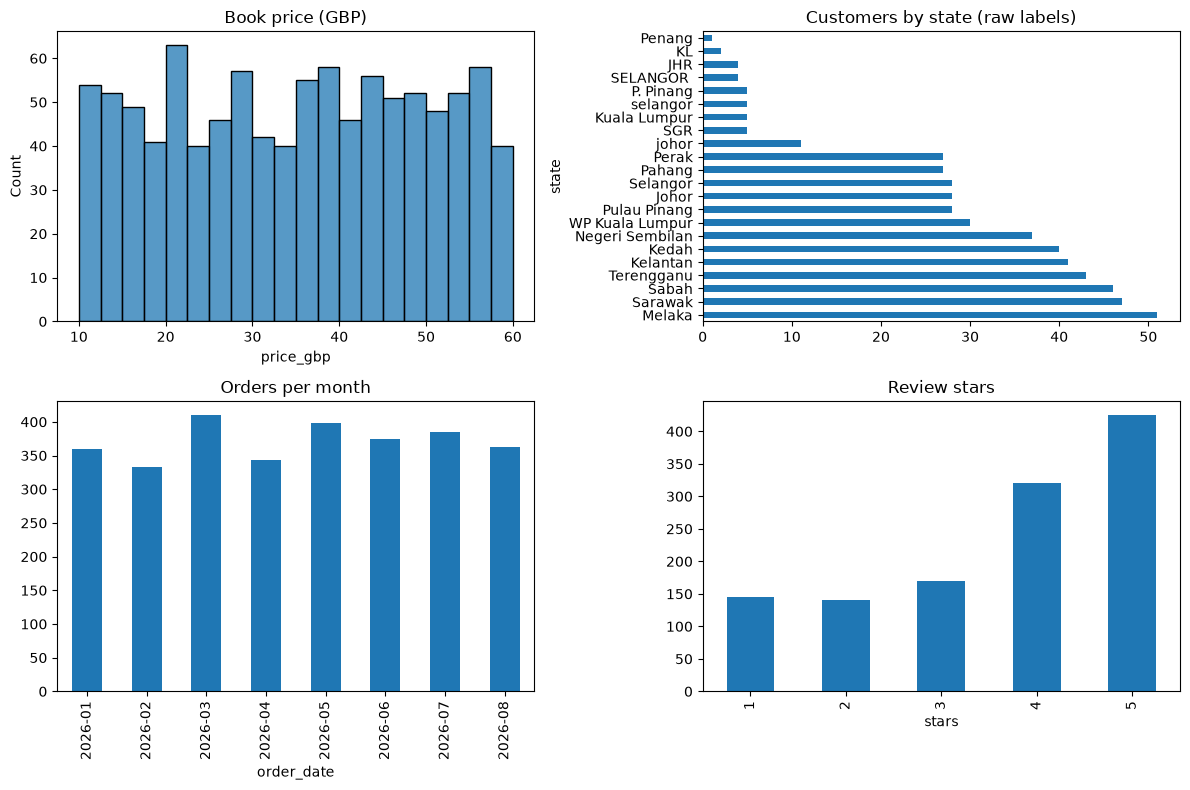

In [23]:
books["price_gbp"] = books["price_raw"].str.replace("£", "", regex=False).astype(float)
orders_ok = orders.assign(order_date=pd.to_datetime(
    orders["order_date"], format="%Y-%m-%d", errors="coerce"))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(books["price_gbp"], bins=20, ax=axes[0, 0]).set_title("Book price (GBP)")
customers["state"].value_counts().plot.barh(ax=axes[0, 1], title="Customers by state (raw labels)")
orders_ok.groupby(orders_ok["order_date"].dt.to_period("M")).size().plot.bar(
    ax=axes[1, 0], title="Orders per month")
reviews["stars"].value_counts().sort_index().plot.bar(ax=axes[1, 1], title="Review stars")
plt.tight_layout()